# A crustal response hidden inside an earthquake wavelet

This notebook actively reconstructs the entire bound **real GE.WLF Tohoku record**, then compares three inverses computed from local source. The vertical trace is a measured source proxy; radial and transverse responses reveal mode-conversion structure. These are finite-band operational responses, **not true velocity/depth maps**.

Instrument-response-corrected velocities are licensed CC BY4.0 (GEOFON, DOI10.14470/TR560404). The selected method is Eulenfeld2020, DOI10.21105/joss.01808. Original results reproduced on this exact acquisition are independently frozen; historical paper figures are not numerical evidence for this run.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd()
if root.name=='notebooks':root=root.parent
assert (root/'data/raw_data.npz').is_file()
sys.path.insert(0,str(root))
from src.preprocessing import load_data,preprocess,SAMPLING_RATE
from src.physics_model import rotate_zne,reconvolution
from src.solvers import waterlevel,time_domain,iterative
from src.main import reconstruct
from src.visualization import make_figures,metrics
raw=load_data(root/'data/raw_data.npz')
display(Markdown(f'Native observations: `{raw.shape}`, `{raw.dtype}`, 20 Hz, full 240 s, calibrated m/s.'))

Native observations: `(3, 4801)`, `float64`, 20 Hz, full 240 s, calibrated m/s.

## Physics and inverse conventions

For each horizontal component, $d[n]=\sum_m s[m]h[n-m]+e[n]$, where $s$ is measured vertical velocity, $d$ is measured radial/transverse velocity, $h$ is a dimensionless discrete response and $e$ is noise/model error. Rotation uses the public station-to-source direction; positive radial motion points away from the source. Both source and response have units m/s.

For signed frequency $f$ in Hz and Fourier transforms $S,D$, the stabilized estimate is $H=G D S^*/\max(|S|^2,\alpha\max |S|^2)$, with $G=\exp[-f^2/(2\sigma^2)]$. Here $\alpha=.05$, $\sigma=.5$Hz; a30s Fourier delay gives negative lags. The common vertical self-response peak sets normalization. Linear detrend,5%-per-side Hann taper and causal fourth-order .05–1Hz bandpass precede inversion. The original5-smooth FFT grid has4860 points. No spatial reconstruction or calibrated interface depth is claimed.

In [2]:
start=time.perf_counter()
fresh=reconstruct(root/'data/raw_data.npz')[0]
zrt=rotate_zne(preprocess(raw))
standard,diag=waterlevel(zrt)
td=time_domain(zrt)[1:]
it,itdiag=iterative(zrt)
sweep={alpha:waterlevel(zrt,waterlevel=alpha)[0][1:] for alpha in (.005,.05,.2)}
runtime=time.perf_counter()-start
with np.load(root/'test/fixtures/upstream_stages.npz',allow_pickle=False) as f:
    original=f['output_reconstruction'][0]; original_td=f['output_time']; original_it=f['output_iterative']
upstream=json.loads((root/'notebooks/reference_outputs/upstream_measurements.json').read_text())
measurements={'fresh_runtime_seconds':runtime,'standard_vs_original':metrics(fresh,original),'time_vs_original_time':metrics(td,original_td),'iterative_vs_original_iterative':metrics(it[1:],original_it),'iterative_counts':itdiag['iterations'],'original_runtime_seconds':upstream['runtime_seconds']}
print(json.dumps(measurements,indent=2))
assert np.max(abs(fresh-original))<1e-10

{
  "fresh_runtime_seconds": 0.2620141999796033,
  "standard_vs_original": {
    "ncc": 1.0000000000000002,
    "nrmse": 8.586852709608908e-15
  },
  "time_vs_original_time": {
    "ncc": 1.0000000000000002,
    "nrmse": 2.399890145535997e-14
  },
  "iterative_vs_original_iterative": {
    "ncc": 1.0,
    "nrmse": 3.2861989189669352e-15
  },
  "iterative_counts": [
    2,
    400,
    400
  ],
  "original_runtime_seconds": 0.3118304000236094
}


## Source extraction and stable converted arrivals

All colored inverse curves below are newly computed. The dashed original curve is the independently executed original standard method on the identical calibrated measurements. Time-domain and iterative comparisons use their own source normalization conventions. Iterative estimates reach the400-update cap and are not labeled converged. Water-level changes test whether weak-band amplification creates an apparently stable conversion. The lag-axis focus view is −15..90 s; full4801-point arrays remain unchanged and are evaluated in full.

### Observations

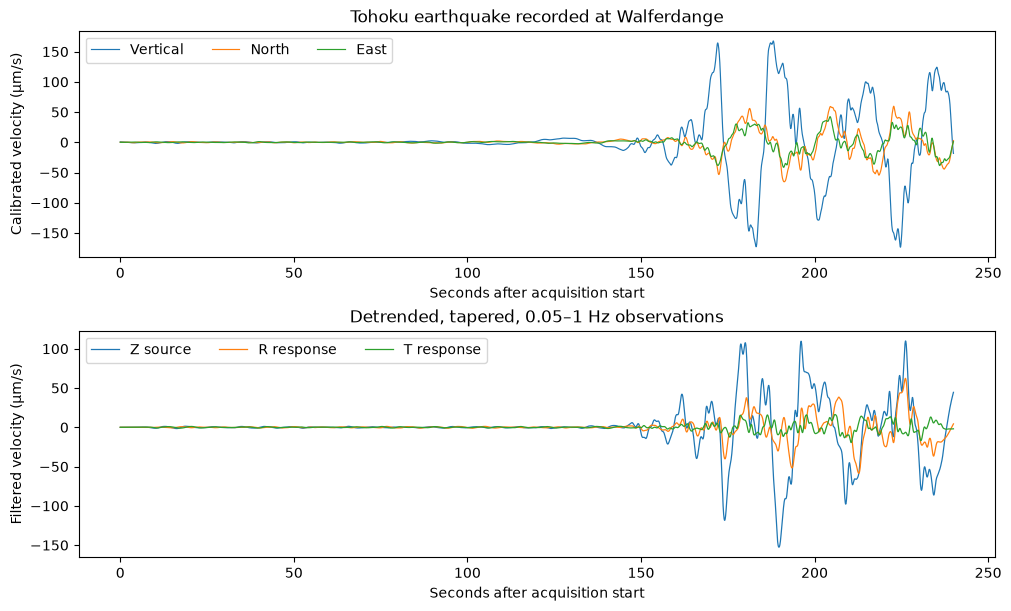

### Receiver comparisons

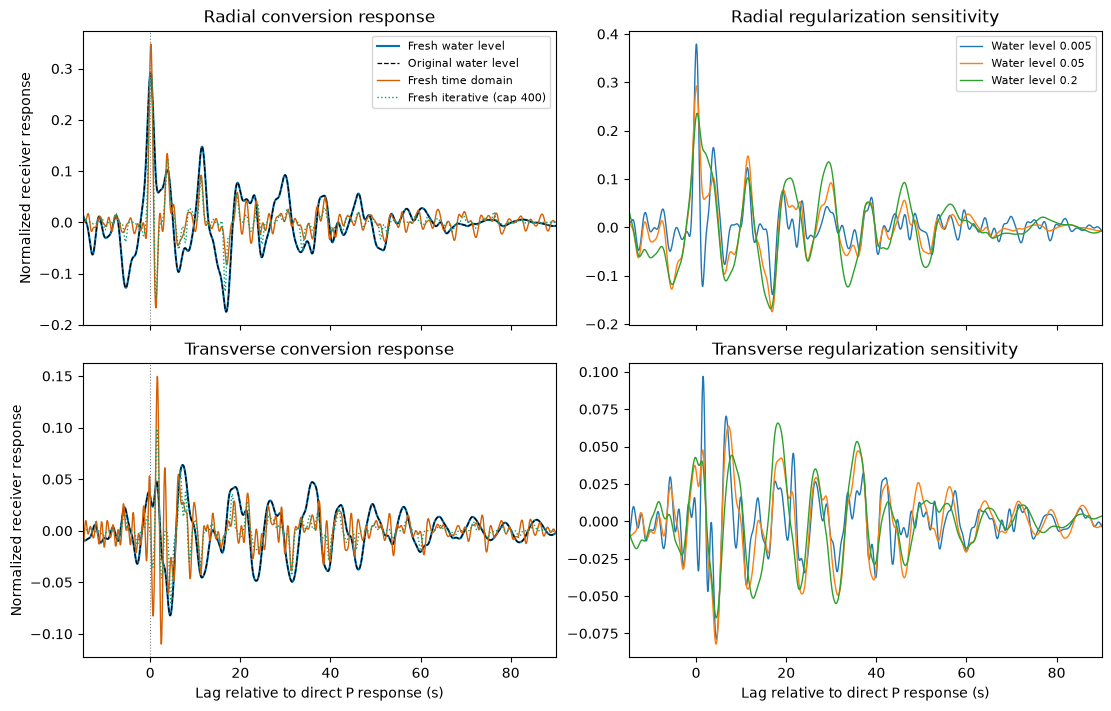

### Forward consistency

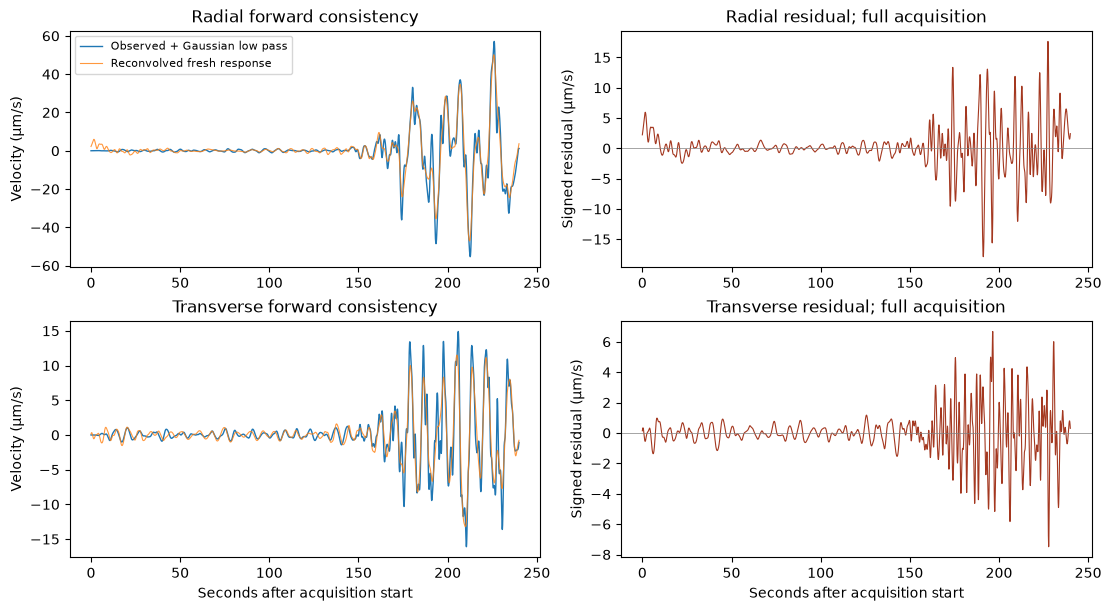

In [3]:
methods={'Fresh water level':fresh,'Original water level':original,'Fresh time domain':td,'Fresh iterative (cap 400)':it[1:]}
plots=make_figures(raw,zrt,methods,sweep,diag['norm'])
plt.close('all')
for name,figure in plots.items():
    display(Markdown('### '+name.replace('_',' ').capitalize()));display(figure);plt.close(figure)

## Bandwidth and acquisition information

A narrower Gaussian lowers temporal resolution and noise amplification. The following curves are full fresh inversions at three bandwidths. A separate acquisition experiment retains every other measured sample (10Hz), then explicitly rebuilds preprocessing and the FFT inverse on that grid; it never changes the native benchmark or uses an archived reconstruction. This tests sampling information, not missing-event generalization.

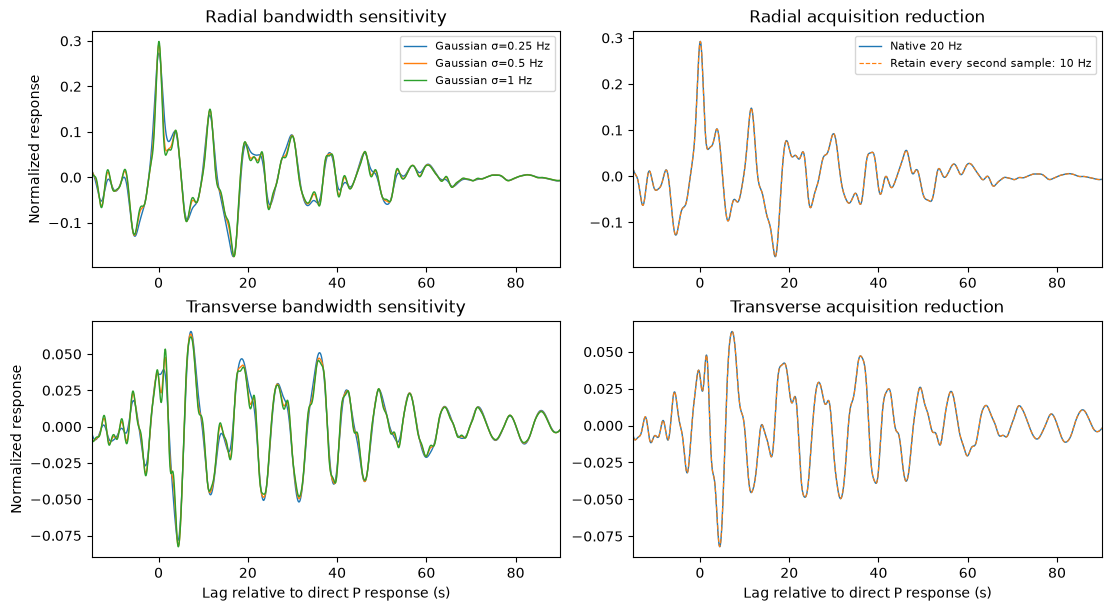

{
  "fresh_runtime_seconds": 0.2620141999796033,
  "standard_vs_original": {
    "ncc": 1.0000000000000002,
    "nrmse": 8.586852709608908e-15
  },
  "time_vs_original_time": {
    "ncc": 1.0000000000000002,
    "nrmse": 2.399890145535997e-14
  },
  "iterative_vs_original_iterative": {
    "ncc": 1.0,
    "nrmse": 3.2861989189669352e-15
  },
  "iterative_counts": [
    2,
    400,
    400
  ],
  "original_runtime_seconds": 0.3118304000236094,
  "relative_reconvolution_residual": [
    0.2865958722978199,
    0.36619354852462543
  ],
  "waterlevel_relative_difference": {
    "0.005": 0.6574845939507962,
    "0.05": 0.0,
    "0.2": 0.5395328294289229
  },
  "bandwidth_relative_difference": {
    "0.25": 0.15558560046084388,
    "0.5": 0.0,
    "1.0": 0.05889995773551147
  }
}


In [4]:
from scipy.signal import detrend,butter,sosfilt
from scipy.signal.windows import hann
from scipy.fftpack import fft,ifft,next_fast_len
bandwidth={sigma:waterlevel(zrt,gauss=sigma)[0][1:] for sigma in (.25,.5,1.)}
reduced=raw[:,::2].copy(); n=reduced.shape[-1];w=int(.05*n);sides=hann(2*w+1)
window=np.r_[sides[:w],np.ones(n-2*w),sides[-w:]]
rz=rotate_zne(sosfilt(butter(4,[.05/5,1/5],btype='bandpass',output='sos'),detrend(reduced,axis=-1)*window,axis=-1))
nf=next_fast_len(n);f=np.fft.fftfreq(nf,.1);s=fft(rz,nf,axis=-1);power=abs(s[0])**2
h=ifft(np.exp(-.5*(f/.5)**2)*np.exp(-2j*np.pi*f*30)*s*np.conj(s[0])/np.maximum(power,.05*power.max()),axis=-1)[...,:n]
reduced_rf=(h/np.max(h[0])).real[1:]
fig,ax=plt.subplots(2,2,figsize=(11,6),layout='constrained')
lag=np.arange(4801)/20-30;rlag=np.arange(n)/10-30
for c,label in enumerate(('Radial','Transverse')):
    for sigma,x in bandwidth.items():ax[c,0].plot(lag,x[c],label=f'Gaussian σ={sigma:g} Hz',lw=1)
    ax[c,0].set(xlim=(-15,90),ylabel='Normalized response',title=label+' bandwidth sensitivity')
    ax[c,1].plot(lag,fresh[c],label='Native 20 Hz',lw=1);ax[c,1].plot(rlag,reduced_rf[c],label='Retain every second sample: 10 Hz',lw=.85,ls='--')
    ax[c,1].set(xlim=(-15,90),title=label+' acquisition reduction')
ax[0,0].legend(fontsize=8);ax[0,1].legend(fontsize=8)
for a in ax[-1]:a.set_xlabel('Lag relative to direct P response (s)')
plt.close(fig);display(fig)
pred,obs=reconvolution(zrt,fresh,diag['norm'])
measurements['relative_reconvolution_residual']=[float(np.linalg.norm(pred[c]-obs[c])/np.linalg.norm(obs[c]))for c in range(2)]
measurements['waterlevel_relative_difference']={str(k):float(np.linalg.norm(v-fresh)/np.linalg.norm(fresh))for k,v in sweep.items()}
measurements['bandwidth_relative_difference']={str(k):float(np.linalg.norm(v-fresh)/np.linalg.norm(fresh))for k,v in bandwidth.items()}
print(json.dumps(measurements,indent=2))

## Independent evaluation and interpretation

The Judge evaluates fresh radial and transverse arrays independently, without sign, translation, rescaling or crop fitting. NCC is uncentered cosine similarity and NRMSE is RMS error divided by each original component's full amplitude range. Tight numerical agreement certifies extraction of the chosen standard method; the original reconstruction is a **method reference**, not a geological ground truth.

Forward residuals expose motion suppressed by source-power clipping, finite-trace truncation and source-proxy mismatch. Their nonzero values are meaningful limitations. No noise variance is known, so no fictitious chi-square is reported. A single station/event and finite bandwidth cannot identify a unique crustal velocity profile. Late source complexity, scattering and transverse energy must not be interpreted as uniquely resolved interfaces. The comparison methods demonstrate sensitivity rather than independent confirmation of geological accuracy.

In [5]:
import importlib.util,tempfile
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with tempfile.TemporaryDirectory() as directory:
    path=Path(directory)/'fresh.npz';np.savez_compressed(path,reconstruction=fresh[None]);report,status=judge.evaluate(path)
print(json.dumps(report,indent=2));assert status==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "radial_ncc": 1.0000000000000002,
    "radial_nrmse": 9.45431809317521e-15,
    "transverse_ncc": 1.0000000000000004,
    "transverse_nrmse": 2.4398416780271447e-14
  },
  "thresholds": {
    "radial_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "radial_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "transverse_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "transverse_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}
